# 1 · Prepare captures for ATHENA (README steps 1 and 2)

Kernel: the `athena` conda env. Run all cells; then continue with `2_run_athena.ipynb`.

Every capture folder in `Dexter/data/` becomes an ATHENA main folder in `Dexter/athena_projects/<capture>/`:

```
athena_projects/<capture>/
├── videos/<capture>/cam0.avi ... cam8.avi   step 1: lossless remux of the Take_*.mkv files
├── calibration/calibration.toml              step 2: camera calibration (names cam0..cam8 = video names)
├── calibration_check.jpg                     floor grid drawn into every camera
├── calibration_report.json                   per-camera errors, focal lengths, positions
├── preview.jpg                               one labelled frame per camera
└── prep_manifest.json                        camera map (cam0 = cam_1 = serial) + recorder checks
```

**Calibration** is computed from the photo of the two checkerboards (10 cm squares) that every camera takes at the start of a capture (`calibration_frames/`). It gives each camera's lens parameters and position, in millimetres, with the origin on the floor board and z pointing up. Details: `calibrate_rig.py`.

Already-done captures are skipped, so just re-run after copying new captures into `data/`.

In [1]:
from pathlib import Path
import json
from IPython.display import Image, display
import prepare_athena as pa

DATA_ROOT = pa.DATA_ROOT   # Dexter/data: drop new capture folders here
OUT_ROOT = pa.OUT_ROOT     # Dexter/athena_projects: one ATHENA main folder per capture
SQUARE_MM = 100.0          # side of one checkerboard square (10 cm)
ONLY = None                # e.g. ["2026-10-20_103853_capture"] to process only some captures

## Step 1 · Organize the videos and compute the calibration

In [2]:
results = pa.prepare_all(DATA_ROOT, OUT_ROOT, only=ONLY, square_mm=SQUARE_MM)

Found 1 capture(s) in /Users/louistschanz/Documents/EPFL/Champalimaud/Dexter/data

== 2026-10-20_103853_capture
    cam0.avi  ok (already done)
    cam1.avi  ok (already done)
    cam2.avi  ok (already done)
    cam3.avi  ok (already done)
    cam4.avi  ok (already done)
    cam5.avi  ok (already done)
    cam6.avi  ok (already done)
    cam7.avi  ok (already done)
    cam8.avi  ok (already done)
    calibrating from the checkerboard snapshot (about a minute)...
    calibration: ok: from checkerboards, worst camera 0.86 px

Summary
  2026-10-20_103853_capture  ok  | calibration ok: from checkerboards, worst camera 0.86 px


## Step 2 · Ensure the calibration files are correct

ATHENA's README requires: camera names in the calibration match the video filenames; intrinsics, distortion and extrinsics present. `check_project` loads the calibration with ATHENA's own reader and checks it against every recording's videos (names, order, frame counts).

In [3]:
for r in results:
    problems = pa.check_project(r["project"])
    print(f"{r['capture']}: " + ("ready for ATHENA" if not problems else "PROBLEMS"))
    for p in problems:
        print("   -", p)

2026-10-20_103853_capture: ready for ATHENA


## Visual checks

- **Calibration check:** a 50 cm grid on the floor plus the world axes (x red, y green, z blue, 1 m long). If the calibration is right, the grid lies flat on the floor and the axes sit on the same corner of the floor board in every view.
- **Preview:** each tile is labelled `athena name = lab name (serial)`. ATHENA's outputs (`landmarks/.../cam0`, `videos_processed/cam0_*.mp4`, ...) use these `cam0..cam8` indices.

2026-10-20_103853_capture  |  ok  |  calibration ok: from checkerboards, worst camera 0.86 px
   cam_1: error 0.55 px, focal 2119 px, position (-675, 1790, 2432) mm
   cam_2: error 0.36 px, focal 1460 px, position (697, 1516, 2423) mm
   cam_3: error 0.43 px, focal 1438 px, position (1647, 1326, 2413) mm
   cam_4: error 0.71 px, focal 2076 px, position (1759, 1134, 2412) mm
   cam_5: error 0.66 px, focal 1464 px, position (1754, -1265, 2436) mm
   cam_6: error 0.73 px, focal 3090 px, position (1297, -1806, 2523) mm
   cam_7: error 0.49 px, focal 1466 px, position (494, -1800, 2443) mm
   cam_8: error 0.40 px, focal 1462 px, position (-944, -1932, 2453) mm
   cam_9: error 0.86 px, focal 1545 px, position (-1570, 1100, 2593) mm


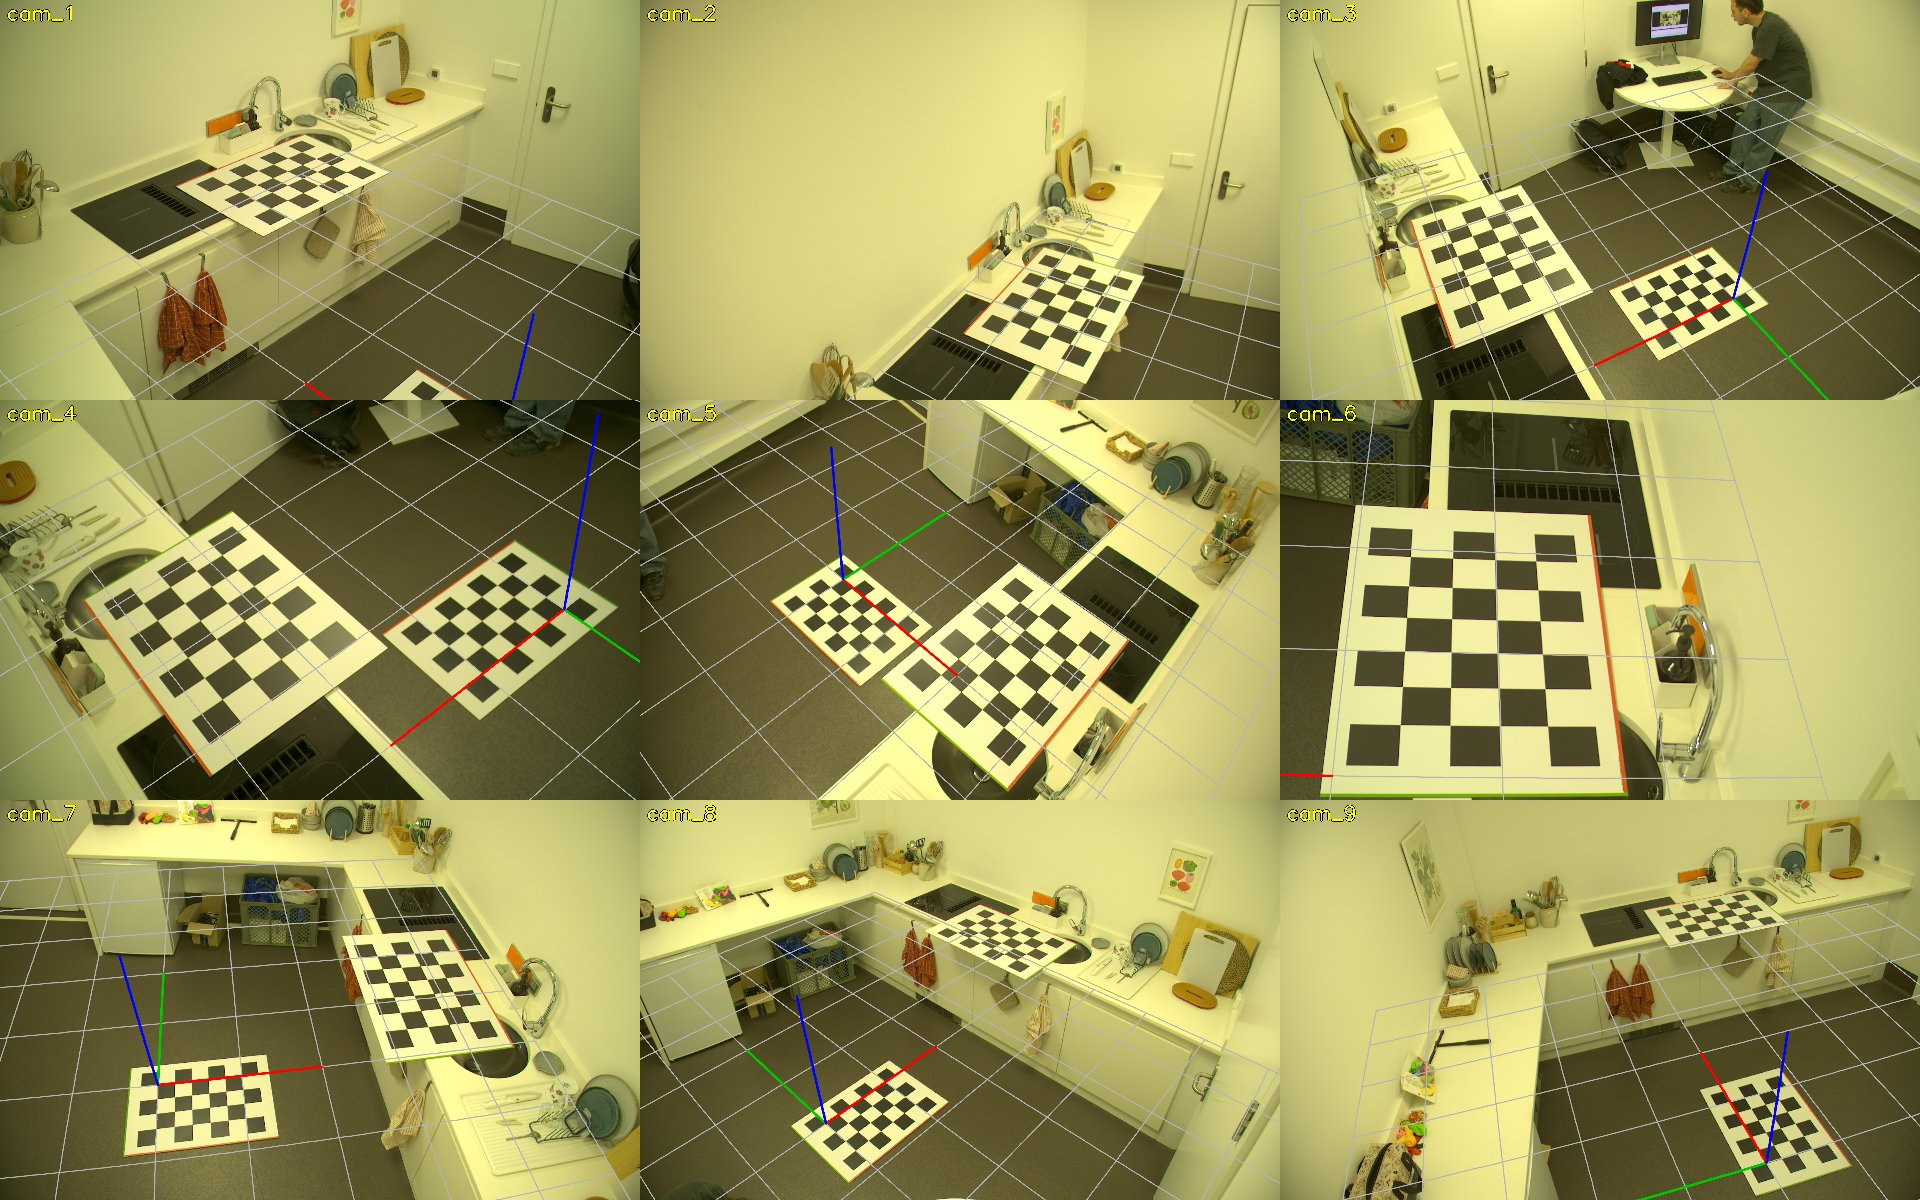

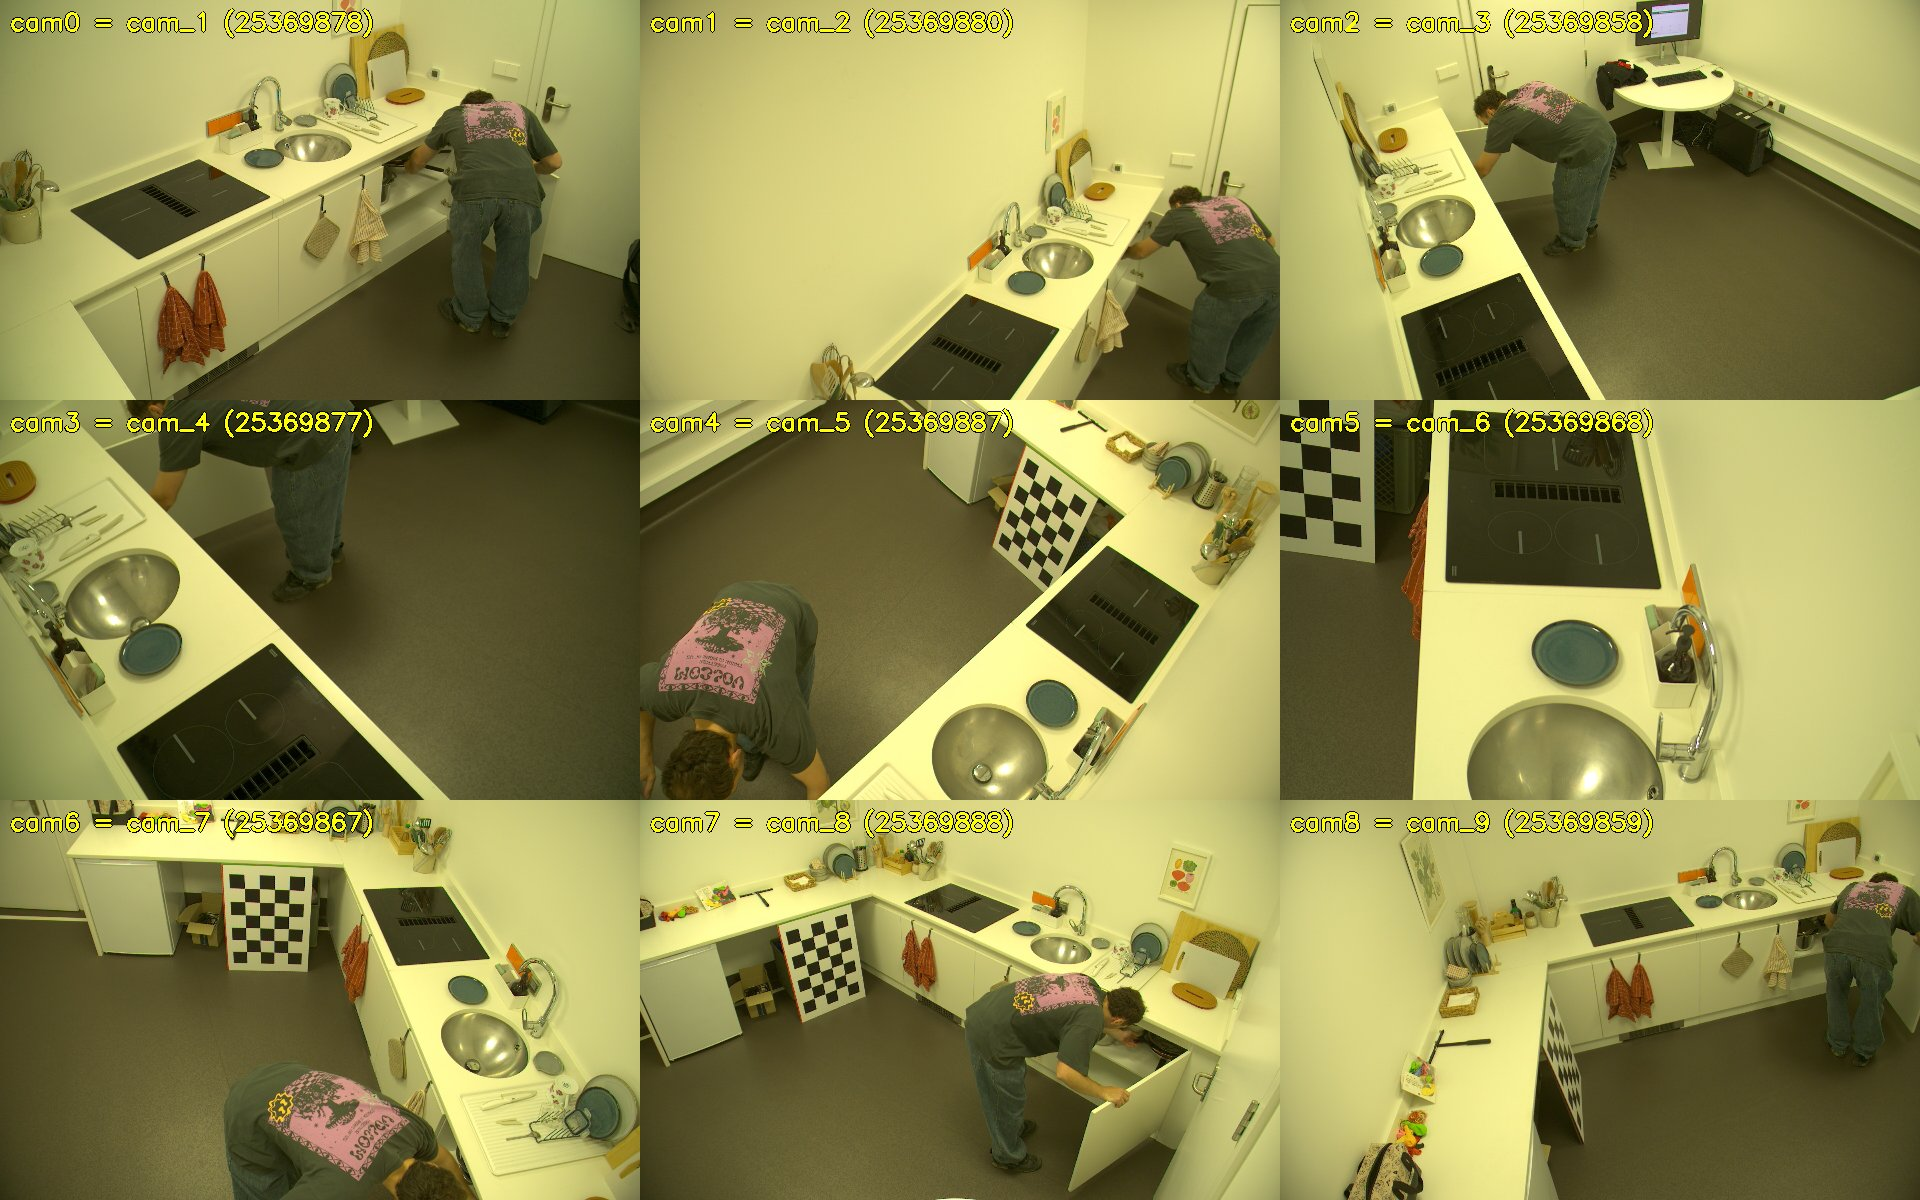

In [4]:
for r in results:
    project = Path(r["project"])
    print(f"{r['capture']}  |  {r['status']}  |  calibration {r['calibration']}")
    for w in r["warnings"]:
        print("   WARNING:", w)
    report = project / "calibration_report.json"
    if report.exists():
        for c in json.loads(report.read_text())["cameras"]:
            x, y, z = c["position_mm"]
            print(f"   {c['camera_name']}: error {c['reprojection_rms_px']:.2f} px, "
                  f"focal {c['focal_px']:.0f} px, position ({x:.0f}, {y:.0f}, {z:.0f}) mm")
    for image in ("calibration_check.jpg", "preview.jpg"):
        if (project / image).exists():
            display(Image(filename=str(project / image), width=900))